# Lab 2 – IoT Data Preprocessing: Cleaning, Normalization & Feature Extraction
**Course:** CSET480 – IoT Analytics | **Program:** B.Tech (5th Sem, Odd 2026) | **Exp No:** 2 | **CO1**
**Name:** Harshit Poonia | **Roll No:** S24CSEU2835 | **Faculty:** Dr Debjani Ghosh

**Objective:** Clean, preprocess and visualize an IoT sensor dataset in Python - handle missing values, remove duplicates and outliers, normalize, and engineer features.

**Pipeline:** Raw CSV → Explore → Visualize (raw) → Remove duplicates → Fix invalid values → Handle missing values → Detect & treat outliers → Normalize → Extract features → Visualize (cleaned)

## Part A – Setting Up the Python Environment

In [1]:
!pip install -q pandas numpy matplotlib scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
print("All libraries imported successfully")

All libraries imported successfully


## Part B – Generating the Practice Dataset
Synthetic 24-hour log (temperature + humidity, every 5 min) with a WiFi-dropout gap, scattered missing values, duplicate MQTT rows, noisy spikes and one impossible humidity value.

In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 288  # 24 hours, 1 reading every 5 minutes
timestamps = pd.date_range("2026-08-21 00:00:00", periods=n, freq="5min")

# Realistic daily temperature curve (cool at night, warm in afternoon)
hours = np.array([t.hour + t.minute/60 for t in timestamps])
true_temp = 24 + 6*np.sin((hours-9)/24*2*np.pi - np.pi/2) + np.random.normal(0, 0.3, n)
true_hum  = np.clip(70 - 1.5*(true_temp-24) + np.random.normal(0, 1.5, n), 30, 95)

df = pd.DataFrame({"timestamp": timestamps, "sensor_id": "ESP32_01",
                   "temperature": true_temp.round(2), "humidity": true_hum.round(2)})

# Inject a WiFi-dropout gap + scattered missing values
df.loc[120:128, ["temperature","humidity"]] = np.nan
df.loc[np.random.choice(n, 6, replace=False), "temperature"] = np.nan

# Inject duplicate rows (simulate MQTT re-publish)
dup_rows = df.iloc[[50, 51, 150]].copy()
df = pd.concat([df.iloc[:52], dup_rows.iloc[[0]], df.iloc[52:151],
                dup_rows.iloc[[2]], df.iloc[151:]], ignore_index=True)

# Inject noisy spikes + one impossible humidity value
spike_idx = np.random.choice(df.index[df["temperature"].notna()], 4, replace=False)
df.loc[spike_idx, "temperature"] += np.random.choice([25,-20,30,-18], 4)
bad_idx = np.random.choice(df.index[df["humidity"].notna()], 1)[0]
df.loc[bad_idx, "humidity"] = 142.0

df.to_csv("iot_sensor_log.csv", index=False)
print("Dataset created:", df.shape)

Dataset created: (290, 4)


## Part C – Loading and Exploring the Dataset

In [4]:
df = pd.read_csv("iot_sensor_log.csv", parse_dates=["timestamp"])

print(df.shape)                      # (rows, columns)
print(df.info())                     # data types, non-null counts
print(df.describe())                 # mean, min, max, etc.
print(df.isnull().sum())             # missing values per column
print(df.duplicated(subset=["sensor_id","timestamp"]).sum())  # duplicate count

(290, 4)
<class 'pandas.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   timestamp    290 non-null    datetime64[us]
 1   sensor_id    290 non-null    str           
 2   temperature  275 non-null    float64       
 3   humidity     281 non-null    float64       
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 9.2 KB
None
                 timestamp  temperature    humidity
count                  290   275.000000  281.000000
mean   2026-08-21 11:56:00    24.081418   69.954342
min    2026-08-21 00:00:00     0.250000   56.760000
25%    2026-08-21 05:56:15    20.275000   63.290000
50%    2026-08-21 11:57:30    24.460000   69.770000
75%    2026-08-21 17:53:45    28.330000   75.590000
max    2026-08-21 23:55:00    47.430000  142.000000
std                    NaN     4.828437    7.849890
timestamp       0
sensor_id       0
temperature    15
humidity  

**Observation (Exploration):**
- The raw file has **290 rows × 4 columns** (288 expected readings + 2 extra rows).
- `describe()` shows humidity **max = 142.0 %**, which is physically impossible (RH ≤ 100 %).
- Temperature ranges from **0.25 °C to 47.43 °C** - far wider than a normal indoor/outdoor day, hinting at spikes.
- `isnull().sum()` reports **15 missing temperature** and **9 missing humidity** values (WiFi dropout + scattered gaps).
- `duplicated()` finds **2 duplicate rows** on `sensor_id + timestamp` (MQTT re-publish).
- So all four problem types - missing, duplicate, invalid, outlier - are confirmed before any cleaning.

## Part D – Visualizing the Raw Data

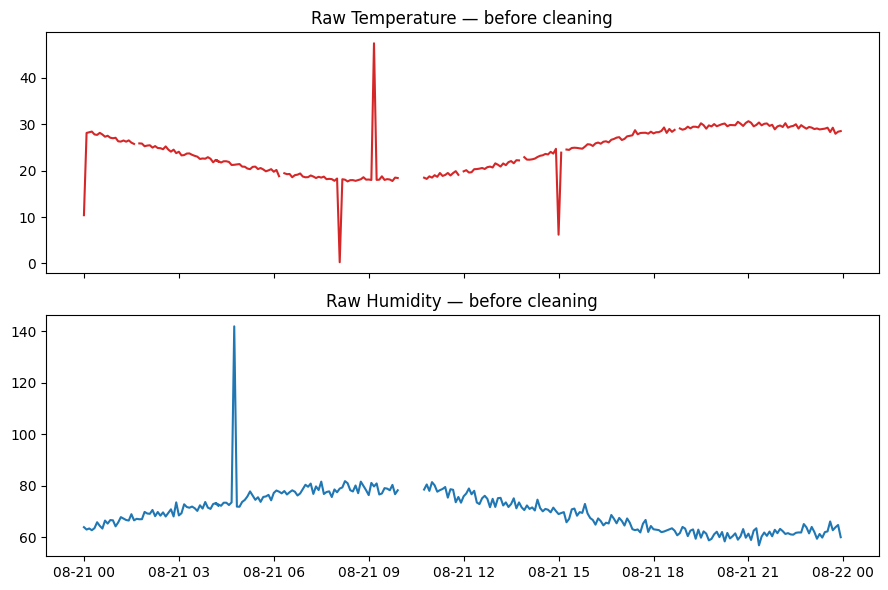

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9,6), sharex=True)
axes[0].plot(df["timestamp"], df["temperature"], color="tab:red")
axes[0].set_title("Raw Temperature - before cleaning")
axes[1].plot(df["timestamp"], df["humidity"], color="tab:blue")
axes[1].set_title("Raw Humidity - before cleaning")
plt.tight_layout(); plt.show()

**Observation (Raw plot):** Both lines break around 10:00–10:40 - the **WiFi-dropout gap**. The temperature plot shows sharp **spikes/dips** (≈47 °C near 09:10, ≈0 °C near 08:05, ≈6 °C near 15:00, ≈10 °C at 00:00). The humidity plot has one **impossible jump to 142 %** around 04:45. Otherwise both follow a smooth daily cycle (temperature low in the morning, high in the evening; humidity inversely related).

## Part E – Removing Duplicate Rows

In [6]:
before = len(df)
df = df.drop_duplicates(subset=["sensor_id","timestamp"]).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. New shape: {df.shape}")

Removed 2 duplicate rows. New shape: (288, 4)


**Observation (Duplicates):**
- **2 duplicate rows** were removed; shape went from 290 → **288 rows**, exactly one reading per 5 minutes for 24 h.
- Duplicates were matched on `sensor_id + timestamp`, not on reading values, so only re-published MQTT messages were dropped.
- Two genuine readings that happen to share the same temperature value are kept.
- Removing them first avoids double-counting when computing statistics (quartiles, means) in later steps.

## Part F – Handling Domain-Invalid Values

In [7]:
invalid_mask = (df["humidity"] < 0) | (df["humidity"] > 100)
print(f"Invalid humidity readings found: {invalid_mask.sum()}")
df.loc[invalid_mask, "humidity"] = np.nan   # treat as missing, fix in Part G

Invalid humidity readings found: 1


**Observation (Invalid values):** **1 invalid humidity reading (142 %)** was found. Since RH can never exceed 100 %, it is not a statistical question - the value is simply wrong, so it was set to NaN. Humidity missing count therefore rises from 9 to 10, and it will be filled by interpolation in Part G.

## Part G – Handling Missing Values

In [8]:
print("Missing before:\n", df.isnull().sum(), "\n")
df["temperature"] = df["temperature"].interpolate(method="linear")
df["humidity"]    = df["humidity"].interpolate(method="linear")

# In case a gap falls at the very start/end (interpolation can't estimate outward)
df["temperature"] = df["temperature"].bfill().ffill()
df["humidity"]    = df["humidity"].bfill().ffill()

print(df.isnull().sum())   # should now show 0 for both columns
df_before_outliers = df.copy()   # kept for Practice Task 2 comparison

Missing before:
 timestamp       0
sensor_id       0
temperature    15
humidity       10
dtype: int64 

timestamp      0
sensor_id      0
temperature    0
humidity       0
dtype: int64


**Observation (Missing values):**
- Before filling: **15 temperature** and **10 humidity** NaNs (9 from the WiFi gap, 6 scattered temperature gaps, 1 invalid humidity).
- After linear interpolation + `bfill/ffill`, both columns show **0 missing values**.
- Interpolation was chosen over mean imputation because sensor readings change gradually: the ~45-min WiFi gap is bridged by a straight line between the readings on either side, following the warming trend.
- Mean imputation would have inserted the daily average (~24 °C) regardless of time of day, creating artificial steps.
- `bfill/ffill` is only a safety net for gaps at the very start or end of the series.

## Part H – Outlier Detection & Treatment (IQR Method)

In [9]:
def treat_outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    outliers = (series < lower) | (series > upper)
    print(f"{series.name}: {outliers.sum()} outliers found (bounds: {lower:.2f} to {upper:.2f})")
    cleaned = series.copy()
    cleaned[outliers] = np.nan
    return cleaned.interpolate(method="linear").bfill().ffill()

df["temperature"] = treat_outliers_iqr(df["temperature"])
df["humidity"]    = treat_outliers_iqr(df["humidity"])

temperature: 3 outliers found (bounds: 6.92 to 41.08)
humidity: 0 outliers found (bounds: 44.14 to 95.43)


**Observation (Outliers):**
- Temperature: **3 outliers** flagged outside **6.92 °C – 41.08 °C** (the 47.43, 0.25 and 6.19 °C spikes); they were replaced by interpolation.
- Humidity: **0 outliers** - its only bad value (142 %) was already handled in Part F.
- **4 spikes were injected, but IQR caught only 3.** The 10.39 °C spike at 00:00 lies *inside* the global bounds (6.92 – 41.08), even though its neighbours are ~28 °C.
- This is the limitation raised in the discussion point: a global method can miss a spike that is abnormal only relative to its neighbours → motivates the local check in Practice Task 2.

## Part I – Normalization (Min-Max Scaling)

In [10]:
scaler = MinMaxScaler()
df[["temperature_norm", "humidity_norm"]] = scaler.fit_transform(df[["temperature", "humidity"]])
print(df[["temperature","temperature_norm","humidity","humidity_norm"]].head())
print("\nNormalized ranges:\n", df[["temperature_norm","humidity_norm"]].agg(["min","max"]))

   temperature  temperature_norm  humidity  humidity_norm
0        10.39          0.000000     63.83       0.282913
1        28.11          0.875062     62.90       0.245698
2        28.25          0.881975     63.32       0.262505
3        28.41          0.889877     62.64       0.235294
4        27.79          0.859259     63.44       0.267307

Normalized ranges:
      temperature_norm  humidity_norm
min               0.0            0.0
max               1.0            1.0


**Observation (Normalization):**
- Min-Max scaling maps each column to **[0, 1]** using x' = (x − min) / (max − min).
- Temperature (°C) and humidity (%) now share the same scale, so neither dominates distance-based algorithms such as KNN.
- The shape of each signal is unchanged - only the units/scale change; original columns are kept alongside `_norm` columns.
- Note: the remaining 10.39 °C spike at 00:00 is now the temperature minimum, so it maps to 0.0 - showing that an undetected outlier also distorts scaling.

## Part J – Feature Extraction (Rolling Window Features)

In [11]:
window = 6   # 6 x 5-minute readings = 30-minute window
df["temp_roll_mean"] = df["temperature"].rolling(window=window, min_periods=1).mean()
df["temp_roll_std"]  = df["temperature"].rolling(window=window, min_periods=1).std().fillna(0)
df["temp_rate_of_change"] = df["temperature"].diff().fillna(0)

df.to_csv("iot_sensor_log_cleaned.csv", index=False)
print(df[["timestamp","temperature","temp_roll_mean","temp_roll_std","temp_rate_of_change"]].head(10))

            timestamp  temperature  temp_roll_mean  temp_roll_std  \
0 2026-08-21 00:00:00        10.39       10.390000       0.000000   
1 2026-08-21 00:05:00        28.11       19.250000      12.529932   
2 2026-08-21 00:10:00        28.25       22.250000      10.271300   
3 2026-08-21 00:15:00        28.41       23.790000       8.934174   
4 2026-08-21 00:20:00        27.79       24.590000       7.941322   
5 2026-08-21 00:25:00        27.69       25.106667       7.214801   
6 2026-08-21 00:30:00        28.13       28.063333       0.274129   
7 2026-08-21 00:35:00        27.78       28.008333       0.295189   
8 2026-08-21 00:40:00        27.30       27.850000       0.381733   
9 2026-08-21 00:45:00        27.50       27.698333       0.282660   

   temp_rate_of_change  
0                 0.00  
1                17.72  
2                 0.14  
3                 0.16  
4                -0.62  
5                -0.10  
6                 0.44  
7                -0.35  
8              

**Observation (Feature extraction):**
- `temp_roll_mean` (30-min window) smooths short-term noise into a trend.
- `temp_roll_std` measures local instability - it is high in the first 30 minutes because the undetected 10.39 °C spike at 00:00 sits inside that window, then drops to small values.
- `temp_rate_of_change` shows +17.7 °C between 00:00 and 00:05 (the spike), then small changes of a few tenths of a degree - a clear signal a model could use to spot anomalies.
- The final clean dataset (288 rows, 9 columns) is saved as **iot_sensor_log_cleaned.csv**.

## Part K – Visualizing Cleaned Data vs Raw Data

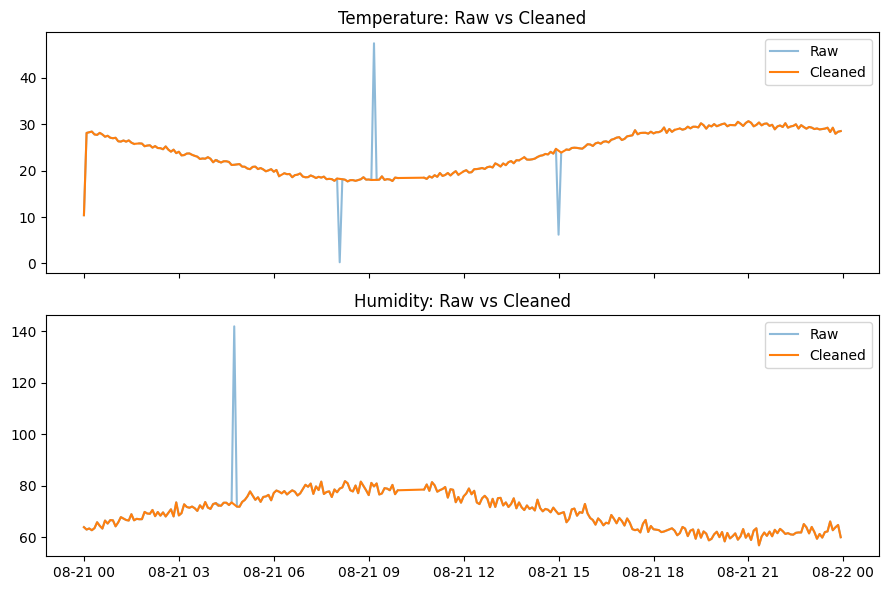

In [12]:
raw = pd.read_csv("iot_sensor_log.csv", parse_dates=["timestamp"])
fig, axes = plt.subplots(2, 1, figsize=(9,6), sharex=True)
axes[0].plot(raw["timestamp"], raw["temperature"], alpha=0.5, label="Raw")
axes[0].plot(df["timestamp"], df["temperature"], linewidth=1.5, label="Cleaned")
axes[0].set_title("Temperature: Raw vs Cleaned"); axes[0].legend()
axes[1].plot(raw["timestamp"], raw["humidity"], alpha=0.5, label="Raw")
axes[1].plot(df["timestamp"], df["humidity"], linewidth=1.5, label="Cleaned")
axes[1].set_title("Humidity: Raw vs Cleaned"); axes[1].legend()
plt.tight_layout(); plt.show()

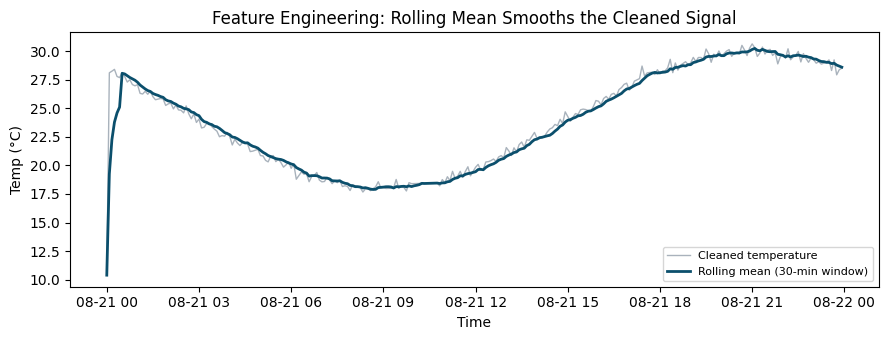

In [13]:
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(df["timestamp"], df["temperature"], color="slategray", alpha=0.6, linewidth=1, label="Cleaned temperature")
ax.plot(df["timestamp"], df["temp_roll_mean"], color="#0b4f6c", linewidth=2, label="Rolling mean (30-min window)")
ax.set_title("Feature Engineering: Rolling Mean Smooths the Cleaned Signal")
ax.set_xlabel("Time"); ax.set_ylabel("Temp (°C)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation (Cleaned vs raw):** The cleaned line has **no gaps, no duplicate points and no impossible values** (humidity stays within ~57–82 %), while following the same daily pattern as the raw data. The rolling-mean line traces a smooth version of the cleaned signal, removing minor noise while preserving the true trend. The one remaining artefact is the dip at 00:00 missed by the global IQR method.

## Result
A raw, messy IoT dataset with missing values (15 temp / 9 humidity), 2 duplicate records, 1 invalid humidity reading and 4 noisy spikes was cleaned, normalized and enriched with rolling-window features using Pandas, NumPy and Scikit-learn. Each step was verified visually with Matplotlib, producing the model-ready file **iot_sensor_log_cleaned.csv** (288 rows).

---
# Practice Tasks for Assessment
## Practice Task 2 – Local / Contextual Outlier Check
Flag any point whose value differs from the **mean of its previous 3 readings** by more than a threshold, and compare with the global IQR method from Part H. Both methods run on the same data (after Part G, before outlier treatment).

In [14]:
THRESH = 3.0   # °C – normal 5-min change is < ~1 °C, so 3 °C is a clear anomaly

def local_outliers(series, k=3, thresh=THRESH):
    prev_mean = series.shift(1).rolling(window=k, min_periods=1).mean()   # mean of previous k readings
    return (series - prev_mean).abs() > thresh

def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75); iqr = q3 - q1
    return (series < q1 - 1.5*iqr) | (series > q3 + 1.5*iqr)

s = df_before_outliers["temperature"]
loc_mask = local_outliers(s)
iqr_mask = iqr_outliers(s)

print(f"Global IQR outliers : {iqr_mask.sum()}")
print(f"Local (prev-3) flags: {loc_mask.sum()}  (threshold = {THRESH} °C)\n")
cmp = pd.DataFrame({"timestamp": df_before_outliers["timestamp"], "temperature": s,
                    "prev3_mean": s.shift(1).rolling(3, min_periods=1).mean().round(2),
                    "IQR": iqr_mask, "Local": loc_mask})
print(cmp[iqr_mask | loc_mask].to_string())

Global IQR outliers : 3
Local (prev-3) flags: 15  (threshold = 3.0 °C)

              timestamp  temperature  prev3_mean    IQR  Local
1   2026-08-21 00:05:00       28.110       10.39  False   True
2   2026-08-21 00:10:00       28.250       19.25  False   True
3   2026-08-21 00:15:00       28.410       22.25  False   True
97  2026-08-21 08:05:00        0.250       18.08   True   True
98  2026-08-21 08:10:00       18.140       12.11  False   True
99  2026-08-21 08:15:00       18.040       12.23  False   True
100 2026-08-21 08:20:00       17.670       12.14  False   True
110 2026-08-21 09:10:00       47.430       18.04   True   True
111 2026-08-21 09:15:00       18.000       27.83  False   True
112 2026-08-21 09:20:00       18.040       27.80  False   True
113 2026-08-21 09:25:00       18.770       27.82  False   True
180 2026-08-21 15:00:00        6.190       24.13   True   True
181 2026-08-21 15:05:00       23.870       18.18  False   True
182 2026-08-21 15:10:00       24.205       18.

The previous-3 check has a blind spot at index 0 (no history), and it also flags the **normal readings right after** a spike, because the spike inflates the previous-3 mean. An improved version compares each point with the median of its 3 neighbours on **each side** (itself excluded), which is robust to a single spike:

Centered local flags: 4
              timestamp  temperature  prev3_mean    IQR  Local  Centered
0   2026-08-21 00:00:00       10.390         NaN  False  False      True
1   2026-08-21 00:05:00       28.110       10.39  False   True     False
2   2026-08-21 00:10:00       28.250       19.25  False   True     False
3   2026-08-21 00:15:00       28.410       22.25  False   True     False
97  2026-08-21 08:05:00        0.250       18.08   True   True      True
98  2026-08-21 08:10:00       18.140       12.11  False   True     False
99  2026-08-21 08:15:00       18.040       12.23  False   True     False
100 2026-08-21 08:20:00       17.670       12.14  False   True     False
110 2026-08-21 09:10:00       47.430       18.04   True   True      True
111 2026-08-21 09:15:00       18.000       27.83  False   True     False
112 2026-08-21 09:20:00       18.040       27.80  False   True     False
113 2026-08-21 09:25:00       18.770       27.82  False   True     False
180 2026-08-21 15:00:00    

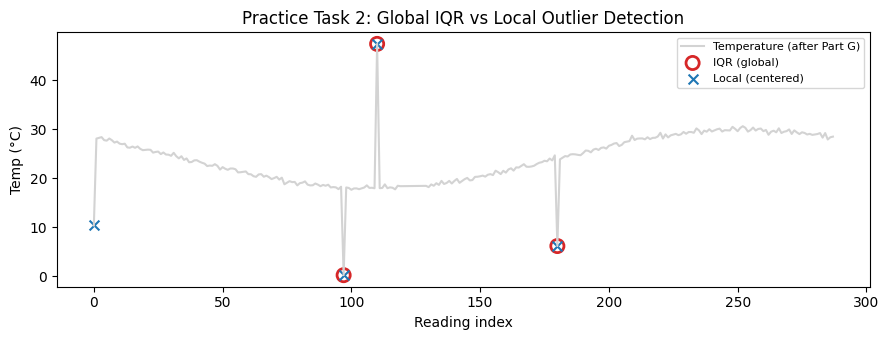

In [15]:
def local_outliers_centered(series, k=3, thresh=THRESH):
    # median of the k readings before AND k readings after (point itself excluded)
    neigh = pd.concat([series.shift(i) for i in range(-k, k+1) if i != 0], axis=1)
    ref = neigh.median(axis=1, skipna=True)   # works at the edges too
    return (series - ref).abs() > thresh

cen_mask = local_outliers_centered(s)
print(f"Centered local flags: {cen_mask.sum()}")
print(cmp.assign(Centered=cen_mask)[iqr_mask | loc_mask | cen_mask].to_string())

fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(s.index, s, color="lightgray", label="Temperature (after Part G)")
ax.scatter(s.index[iqr_mask], s[iqr_mask], s=90, facecolors="none", edgecolors="tab:red", linewidths=2, label="IQR (global)")
ax.scatter(s.index[cen_mask], s[cen_mask], marker="x", color="tab:blue", s=50, label="Local (centered)")
ax.set_title("Practice Task 2: Global IQR vs Local Outlier Detection"); ax.set_xlabel("Reading index"); ax.set_ylabel("Temp (°C)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Observation (Task 2 – Global vs Local):**
- **Global IQR** flagged **3** points (0.25, 47.43, 6.19 °C) and missed the 10.39 °C spike at 00:00 because it lies inside the global bounds (6.92–41.08 °C).
- The **previous-3 check** (threshold 3 °C) raised **15** flags: it catches every spike *arriving*, but also falsely flags the 3 normal readings after each spike (the spike pulls the previous-3 mean away), and it cannot judge index 0 at all since it has no history.
- The **centered local check** (median of 3 before + 3 after) flagged exactly **4** points - all 4 injected spikes including the one IQR missed - with **0 false positives**.
- Conclusion: global IQR is good for extreme values across the day; a local, neighbour-based check catches context-dependent spikes. A robust pipeline should combine both.

## Practice Task 1 – Using Your Own Lab 1 Data
Export the MQTT readings from Node-RED with a **file** node (CSV: `timestamp,sensor_id,temperature,humidity`), upload it to Colab as `my_lab1_log.csv`, then run the cell below - it repeats Parts C–K on the real data.

In [16]:
import os
REAL = "my_lab1_log.csv"
if os.path.exists(REAL):
    r = pd.read_csv(REAL, parse_dates=["timestamp"])
    print("Raw:", r.shape); print(r.describe()); print(r.isnull().sum())
    print("Duplicates:", r.duplicated(subset=["sensor_id","timestamp"]).sum())
    r = r.drop_duplicates(subset=["sensor_id","timestamp"]).sort_values("timestamp").reset_index(drop=True)
    r.loc[(r["humidity"] < 0) | (r["humidity"] > 100), "humidity"] = np.nan
    for c in ["temperature","humidity"]:
        r[c] = r[c].interpolate().bfill().ffill()
        r[c] = treat_outliers_iqr(r[c])
    r[["temperature_norm","humidity_norm"]] = MinMaxScaler().fit_transform(r[["temperature","humidity"]])
    r["temp_roll_mean"] = r["temperature"].rolling(6, min_periods=1).mean()
    r["temp_roll_std"]  = r["temperature"].rolling(6, min_periods=1).std().fillna(0)
    r["temp_rate_of_change"] = r["temperature"].diff().fillna(0)
    r.to_csv("my_lab1_log_cleaned.csv", index=False)
    fig, ax = plt.subplots(figsize=(9,3.5))
    ax.plot(r["timestamp"], r["temperature"], alpha=.6, label="Cleaned"); ax.plot(r["timestamp"], r["temp_roll_mean"], label="Rolling mean")
    ax.set_title("Lab 1 real data – cleaned"); ax.legend(); plt.tight_layout(); plt.show()
else:
    print(f"'{REAL}' not found - upload your Lab 1 Node-RED CSV export and re-run this cell.")

'my_lab1_log.csv' not found - upload your Lab 1 Node-RED CSV export and re-run this cell.


**Observation (Task 1 – fill in after running on your real data):** Compare which issues appear in the real ESP32/DHT log vs the synthetic one - typically real logs show irregular timestamps, NaN/"nan" strings from failed DHT reads, occasional duplicate MQTT messages, and fewer extreme spikes than the synthetic data.